# Coffee Sales: Data Processing & Analysis

This notebook cleans and analyzes transaction-level sales from a coffee vending/kiosk dataset (March 2024 to March 2025). It answers practical business questions:

1. How much did we sell, and how did sales change over time?
2. Which drinks drive volume and revenue?
3. When are the busy days and hours?
4. How do customers pay, and how loyal are card customers?
5. Did prices change, and how does that affect revenue trends?

**Columns:** `date`, `datetime`, `cash_type`, `card` (anonymized card ID), `money` (amount paid), `coffee_name`.

> The dataset does not state the currency, so amounts are shown as plain "money" units.

## 1. Setup

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

# Consistent, readable plot style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# Fixed ordering for weekday charts
WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

## 2. Load & Inspect

In [4]:
DATA_PATH = r"C:\Users\The Master\Downloads\coffee-sales.csv"

# parse_dates converts the text columns to real datetimes while loading
df = pd.read_csv(DATA_PATH, parse_dates=["date", "datetime"])

print("Shape:", df.shape)
df.head()

Shape: (3636, 6)


,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte


In [5]:
# Column types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3636 entries, 0 to 3635
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         3636 non-null   datetime64[ns]
 1   datetime     3636 non-null   datetime64[ns]
 2   cash_type    3636 non-null   object        
 3   card         3547 non-null   object        
 4   money        3636 non-null   float64       
 5   coffee_name  3636 non-null   object        
dtypes: datetime64[ns](2), float64(1), object(3)
memory usage: 170.6+ KB


In [6]:
# Summary statistics for the numeric column and the text columns
display(df[["money"]].describe().T)
display(df.describe(include="object" if df["coffee_name"].dtype == "object" else "str").T)

,count,mean,std,min,25%,50%,75%,max
money,3636.0,31.746859,4.919926,18.12,27.92,32.82,35.76,40.0


,count,unique,top,freq
cash_type,3636,2,card,3547
card,3547,1316,ANON-0000-0000-0012,129
coffee_name,3636,8,Americano with Milk,824


## 3. Data Cleaning

### 3.1 Missing values, duplicates and consistency checks

In [7]:
# Count and percentage of missing values per column
missing = pd.DataFrame({"missing": df.isna().sum(), "percent": (df.isna().mean() * 100).round(1)})
missing

,missing,percent
date,0,0.0
datetime,0,0.0
cash_type,0,0.0
card,89,2.4
money,0,0.0
coffee_name,0,0.0


Only `card` has missing values. Let's check whether they are simply **cash purchases** (cash payments have no card to record).

In [8]:
# Cross-tab of payment type vs. whether a card ID exists
pd.crosstab(df["cash_type"], df["card"].isna(), rownames=["cash_type"], colnames=["card is missing"])

card is missing,False,True
cash_type,,
card,3547,0
cash,0,89


In [9]:
# Every missing card ID should be a cash payment - assert fails loudly if not
assert df.loc[df["card"].isna(), "cash_type"].eq("cash").all()

# So the missing values are expected, not errors. We label them explicitly.
df["card"] = df["card"].fillna("CASH (no card)")

# Other integrity checks
print("Duplicate rows:              ", df.duplicated().sum())
print("Duplicate timestamps:        ", df["datetime"].duplicated().sum())
print("Non-positive amounts:        ", (df["money"] <= 0).sum())
print("Date column matches datetime:", (df["date"] == df["datetime"].dt.normalize()).all())
print("Date range:                  ", df["date"].min().date(), "to", df["date"].max().date())

Duplicate rows:               0
Duplicate timestamps:         0
Non-positive amounts:         0
Date column matches datetime: True
Date range:                   2024-03-01 to 2025-03-23


### 3.2 Check coverage: are there days without sales?

In [10]:
# Compare every calendar day in the range with the days that have sales
all_days = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
missing_days = all_days.difference(df["date"].unique())

print(f"Calendar days in range: {len(all_days)}")
print(f"Days with sales:        {df['date'].nunique()}")
print(f"Days with no sales:     {len(missing_days)}")
print([d.strftime("%Y-%m-%d") for d in missing_days])

Calendar days in range: 388
Days with sales:        381
Days with no sales:     7
['2024-05-01', '2024-05-04', '2024-05-05', '2024-11-27', '2025-01-01', '2025-01-19', '2025-01-23']


A few days have no records (closures or missing data). When we compute **daily averages** later we divide by days with sales, and we reindex to include zero-sale days only where noted.

### 3.3 Feature engineering

In [11]:
data = df.copy()

# Time-based features extracted from the timestamp
data["year_month"] = data["date"].dt.to_period("M")
data["weekday"]    = data["datetime"].dt.day_name()
data["hour"]       = data["datetime"].dt.hour
data["is_weekend"] = data["datetime"].dt.dayofweek >= 5

# Part of day, to compare morning / afternoon / evening behaviour
data["part_of_day"] = pd.cut(
    data["hour"],
    bins=[0, 12, 17, 24],
    labels=["Morning (<12)", "Afternoon (12-16)", "Evening (17+)"],
    right=False,
)

data.head()

,date,datetime,cash_type,card,money,coffee_name,year_month,weekday,hour,is_weekend,part_of_day
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte,2024-03,Friday,10,False,Morning (<12)
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate,2024-03,Friday,12,False,Afternoon (12-16)
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate,2024-03,Friday,12,False,Afternoon (12-16)
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano,2024-03,Friday,13,False,Afternoon (12-16)
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte,2024-03,Friday,13,False,Afternoon (12-16)


## 4. Exploratory Data Analysis

### 4.1 Headline numbers

In [12]:
total_revenue = data["money"].sum()
n_sales       = len(data)
n_days        = data["date"].nunique()

print(f"Total revenue:               {total_revenue:,.2f}")
print(f"Number of transactions:      {n_sales:,}")
print(f"Average transaction value:   {data['money'].mean():.2f}")
print(f"Average revenue per day:     {total_revenue / n_days:,.2f}")
print(f"Average transactions per day:{n_sales / n_days:,.1f}")

Total revenue:               115,431.58
Number of transactions:      3,636
Average transaction value:   31.75
Average revenue per day:     302.97
Average transactions per day:9.5


### 4.2 Product performance

In [13]:
# Revenue, volume and share for each drink
products = (data.groupby("coffee_name")
                .agg(revenue=("money", "sum"), cups=("money", "size"), avg_price=("money", "mean"))
                .sort_values("revenue", ascending=False))
products["revenue_share_%"] = (products["revenue"] / products["revenue"].sum() * 100).round(1)
products["cups_share_%"]    = (products["cups"] / products["cups"].sum() * 100).round(1)
products.round(2)

,revenue,cups,avg_price,revenue_share_%,cups_share_%
coffee_name,,,,,
Latte,27866.30,782,35.63,24.1,21.5
Americano with Milk,25269.12,824,30.67,21.9,22.7
Cappuccino,18034.14,501,36.00,15.6,13.8
Americano,15062.26,578,26.06,13.0,15.9
Hot Chocolate,10172.46,282,36.07,8.8,7.8
Cocoa,8678.16,243,35.71,7.5,6.7
Cortado,7534.86,292,25.80,6.5,8.0
Espresso,2814.28,134,21.00,2.4,3.7


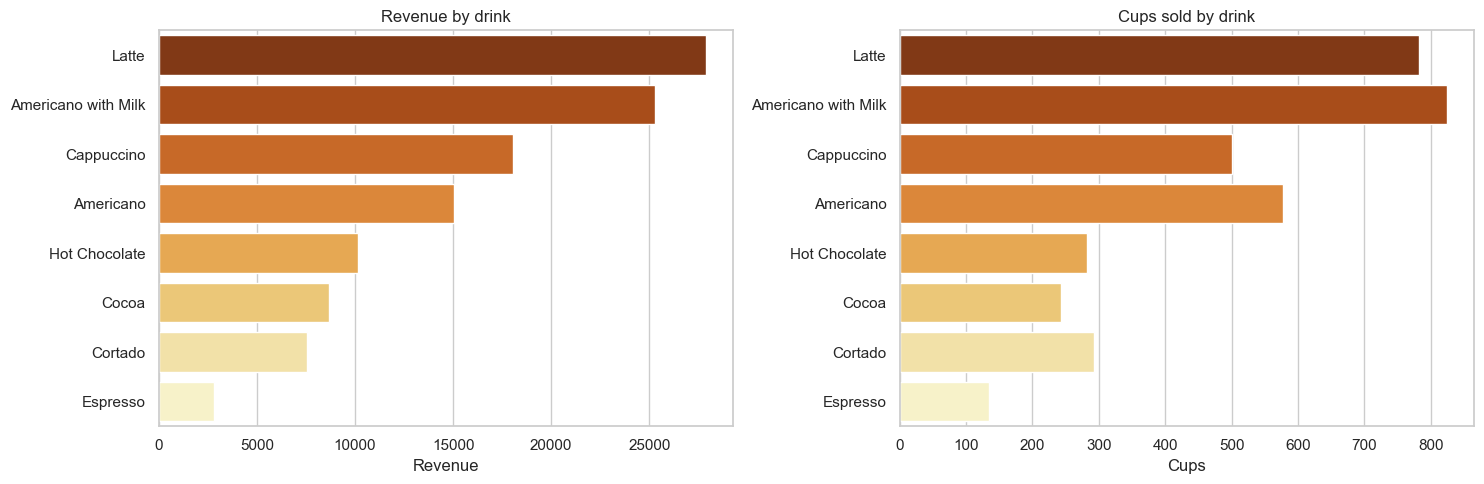

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Revenue by drink
sns.barplot(data=products.reset_index(), y="coffee_name", x="revenue", ax=axes[0],
            palette="YlOrBr_r", hue="coffee_name", legend=False)
axes[0].set_title("Revenue by drink")
axes[0].set_xlabel("Revenue"); axes[0].set_ylabel("")

# Cups sold by drink (same order so the charts are comparable)
sns.barplot(data=products.reset_index(), y="coffee_name", x="cups", ax=axes[1],
            palette="YlOrBr_r", hue="coffee_name", legend=False)
axes[1].set_title("Cups sold by drink")
axes[1].set_xlabel("Cups"); axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Observation:** Latte and Americano with Milk are the top two products by both revenue and volume. Espresso sells the least and is the cheapest drink, so it contributes very little revenue.

### 4.3 Sales over time

In [15]:
# Monthly revenue and cup count
monthly = data.groupby("year_month").agg(revenue=("money", "sum"), cups=("money", "size"),
                                         days=("date", "nunique"))
monthly["revenue_per_day"] = monthly["revenue"] / monthly["days"]
monthly.index = monthly.index.astype(str)
monthly.round(1)

,revenue,cups,days,revenue_per_day
year_month,,,,
2024-03,7050.2,206,31,227.4
2024-04,6720.6,196,30,224.0
2024-05,9063.4,267,28,323.7
2024-06,7758.8,227,30,258.6
2024-07,6915.9,237,31,223.1
2024-08,7613.8,272,31,245.6
2024-09,9988.6,344,30,333.0
2024-10,13891.2,426,31,448.1
2024-11,8590.5,259,29,296.2


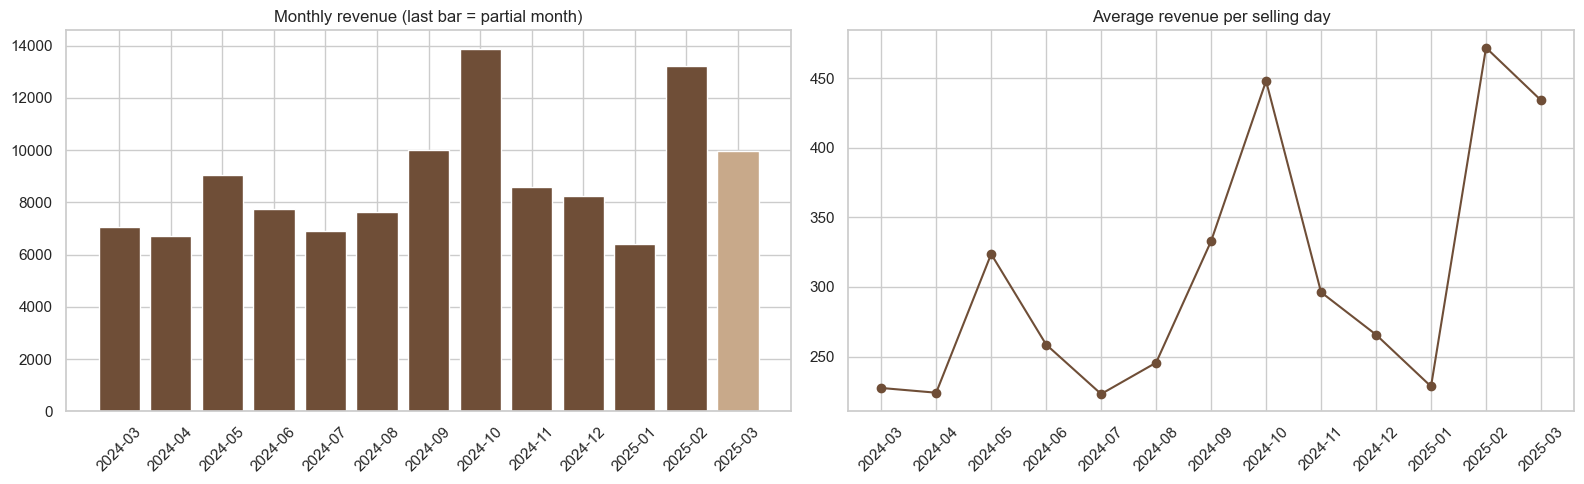

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Total monthly revenue. The last month is incomplete, so we colour it differently.
colors = ["#6f4e37"] * (len(monthly) - 1) + ["#c8a98a"]
axes[0].bar(monthly.index, monthly["revenue"], color=colors)
axes[0].set_title("Monthly revenue (last bar = partial month)")
axes[0].tick_params(axis="x", rotation=45)

# Revenue per selling day removes the effect of unequal month lengths / partial months
axes[1].plot(monthly.index, monthly["revenue_per_day"], marker="o", color="#6f4e37")
axes[1].set_title("Average revenue per selling day")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

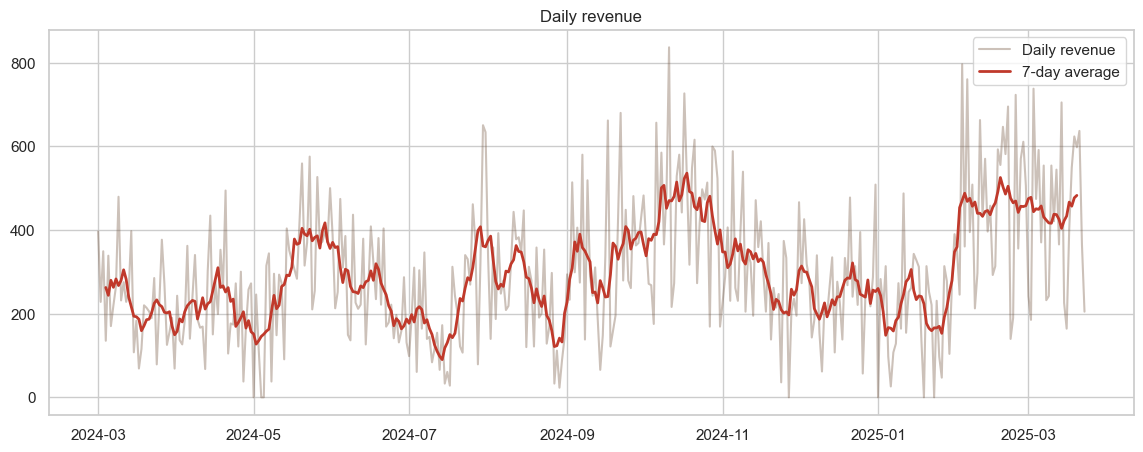

count    388.0
mean     297.5
std      163.4
min        0.0
25%      184.6
50%      272.8
75%      385.8
max      836.7
Name: money, dtype: float64


In [17]:
# Daily revenue with a 7-day rolling average to smooth day-to-day noise
daily = data.groupby("date")["money"].sum().reindex(all_days, fill_value=0)
rolling = daily.rolling(7, center=True).mean()

plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values, alpha=0.35, color="#6f4e37", label="Daily revenue")
plt.plot(rolling.index, rolling.values, color="#c0392b", linewidth=2, label="7-day average")
plt.title("Daily revenue")
plt.legend()
plt.show()

print(daily.describe().round(1))

**Observation:** Sales are seasonal and uneven. The strongest months are October and February, while April, July and January are the weakest. Because the last month (March 2025) is incomplete, compare it using revenue per day rather than the monthly total.

### 4.4 Weekly and hourly patterns

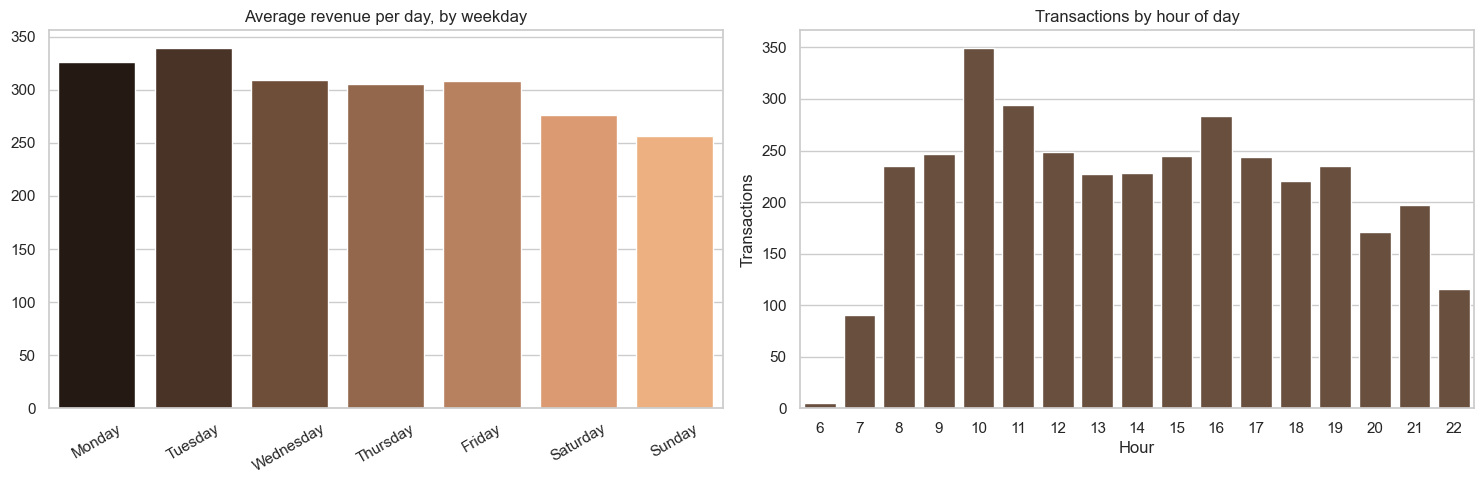

In [18]:
# Average revenue per weekday = total revenue / number of such weekdays with sales
by_day = (data.groupby("weekday")
              .apply(lambda g: g["money"].sum() / g["date"].nunique(), include_groups=False)
              .reindex(WEEKDAY_ORDER))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(x=by_day.index, y=by_day.values, ax=axes[0], palette="copper", hue=by_day.index, legend=False)
axes[0].set_title("Average revenue per day, by weekday")
axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=30)

# Number of transactions by hour of day
hourly = data.groupby("hour").size()
sns.barplot(x=hourly.index, y=hourly.values, ax=axes[1], color="#6f4e37")
axes[1].set_title("Transactions by hour of day")
axes[1].set_xlabel("Hour"); axes[1].set_ylabel("Transactions")

plt.tight_layout()
plt.show()

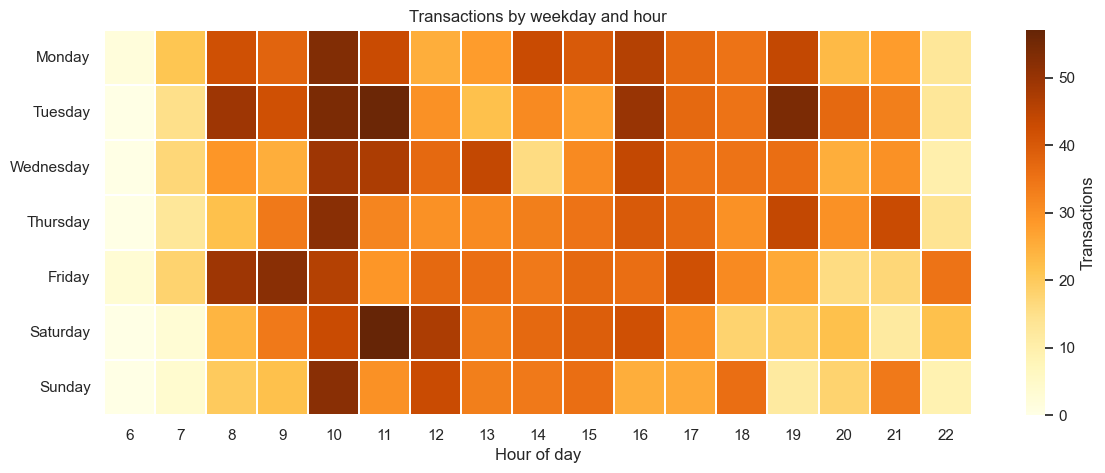

In [19]:
# Heatmap: when exactly is the shop busiest? (weekday x hour, transaction counts)
heat = (data.pivot_table(index="weekday", columns="hour", values="money", aggfunc="size", fill_value=0)
            .reindex(WEEKDAY_ORDER))

plt.figure(figsize=(14, 5))
sns.heatmap(heat, cmap="YlOrBr", linewidths=0.3, cbar_kws={"label": "Transactions"})
plt.title("Transactions by weekday and hour")
plt.xlabel("Hour of day"); plt.ylabel("")
plt.show()

**Observation:** Weekdays are busier than weekends, with Sunday the quietest. The busiest hour is 10:00, with a smaller bump around 16:00 and steady sales into the evening.

### 4.5 What sells when?

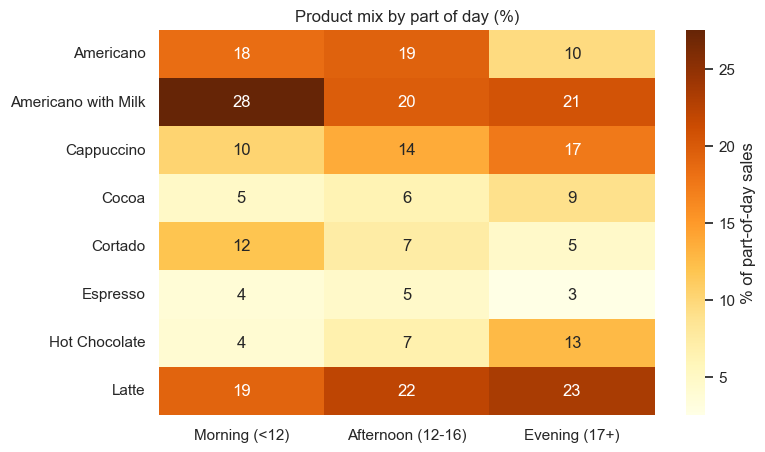

In [20]:
# Product mix within each part of the day (each column sums to 100%)
mix = pd.crosstab(data["coffee_name"], data["part_of_day"], normalize="columns") * 100

plt.figure(figsize=(8, 5))
sns.heatmap(mix, annot=True, fmt=".0f", cmap="YlOrBr", cbar_kws={"label": "% of part-of-day sales"})
plt.title("Product mix by part of day (%)")
plt.ylabel("")
plt.xlabel("")
plt.show()

Cortado and Americano with Milk skew toward the **morning**, while Cappuccino, Cocoa and Hot Chocolate become more popular in the **evening**. We test below whether this difference is statistically real.

### 4.6 Payment type

In [21]:
payment = (data.groupby("cash_type")
               .agg(transactions=("money", "size"), revenue=("money", "sum"), avg_value=("money", "mean")))
payment["transactions_%"] = (payment["transactions"] / payment["transactions"].sum() * 100).round(1)
payment.round(2)

,transactions,revenue,avg_value,transactions_%
cash_type,,,,
card,3547,112245.58,31.65,97.6
cash,89,3186.00,35.80,2.4


Card dominates (about 98% of transactions). Cash purchases are rare, so their average value should be interpreted with care.

### 4.7 Price analysis

The same drink is sold at several different prices across the year. Let's look at how prices changed, because price changes affect revenue independently of how many cups were sold.

In [22]:
# Number of distinct prices per drink and the range
data.groupby("coffee_name")["money"].agg(["min", "max", "nunique"]).round(2)

,min,max,nunique
coffee_name,,,
Americano,23.02,30.0,6
Americano with Milk,27.92,35.0,6
Cappuccino,32.82,40.0,6
Cocoa,32.82,40.0,6
Cortado,23.02,30.0,5
Espresso,18.12,25.0,5
Hot Chocolate,32.82,40.0,6
Latte,32.82,40.0,6


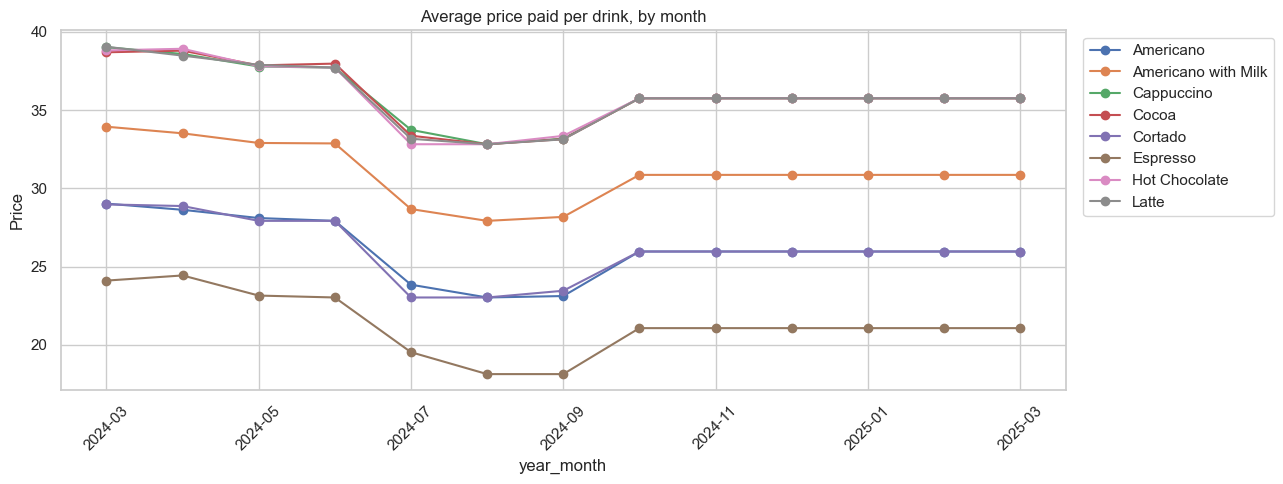

In [23]:
# Average monthly price for each drink
price_trend = (data.pivot_table(index="year_month", columns="coffee_name", values="money", aggfunc="mean"))
price_trend.index = price_trend.index.astype(str)

price_trend.plot(figsize=(13, 5), marker="o", linewidth=1.5)
plt.title("Average price paid per drink, by month")
plt.ylabel("Price")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observation:** Prices drop in mid-2024 (around July to September) and rise again from October onward, with a single stable price afterward. Rather than assuming these are errors, we treat them as real price changes. This means part of the revenue movement over time comes from pricing, not only from demand. Compare **cups sold** and **revenue** together to separate the two.

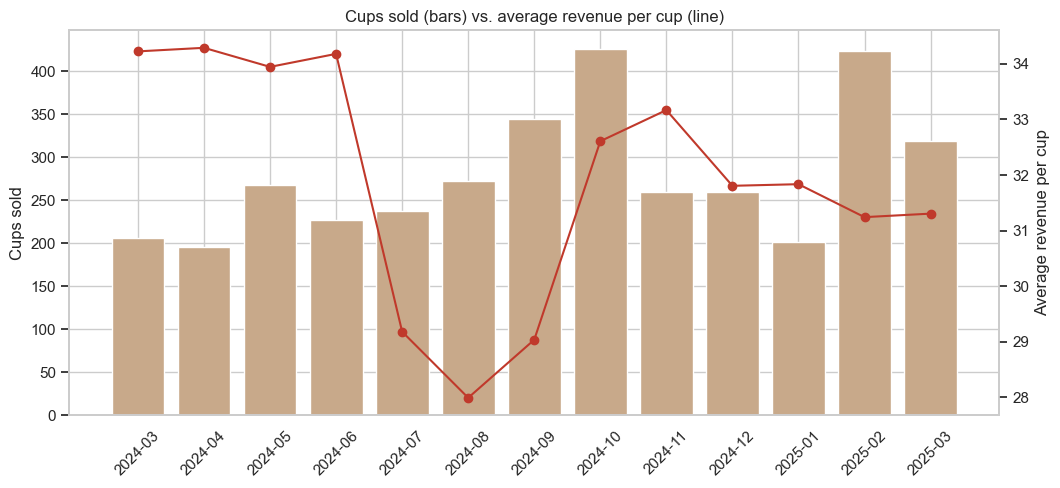

In [24]:
# Volume vs. revenue by month: do they move together?
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(monthly.index, monthly["cups"], color="#c8a98a", label="Cups sold")
ax1.set_ylabel("Cups sold")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["revenue"] / monthly["cups"], color="#c0392b", marker="o", label="Avg revenue per cup")
ax2.set_ylabel("Average revenue per cup")
ax2.grid(False)

ax1.set_title("Cups sold (bars) vs. average revenue per cup (line)")
plt.show()

### 4.8 Customers (card IDs)

Card IDs are anonymized, but they still let us measure repeat purchases. Cash buyers cannot be tracked and are excluded.

In [25]:
# Only card payments carry a customer identifier
cards = data[data["cash_type"] == "card"]
per_customer = cards.groupby("card").agg(purchases=("money", "size"), spend=("money", "sum"),
                                         first=("date", "min"), last=("date", "max"))

n_customers = len(per_customer)
repeat = (per_customer["purchases"] > 1).mean() * 100
repeat_share = per_customer.loc[per_customer["purchases"] > 1, "purchases"].sum() / per_customer["purchases"].sum() * 100

print(f"Unique card customers:            {n_customers:,}")
print(f"Customers who bought more than once: {repeat:.1f}%")
print(f"Share of card sales from repeat customers: {repeat_share:.1f}%")
print(f"Median purchases per customer:    {per_customer['purchases'].median():.0f}")
print(f"Max purchases by one card:        {per_customer['purchases'].max()}")

Unique card customers:            1,316
Customers who bought more than once: 41.4%
Share of card sales from repeat customers: 78.3%
Median purchases per customer:    1
Max purchases by one card:        129


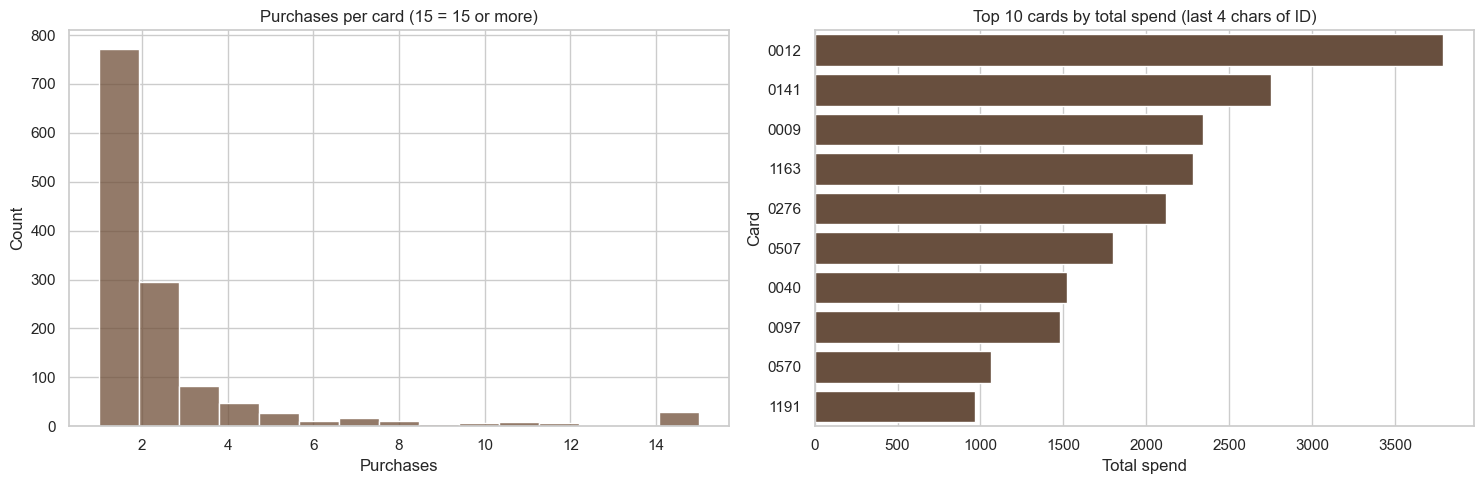

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribution of purchases per customer (capped at 15 for readability)
sns.histplot(per_customer["purchases"].clip(upper=15), bins=15, ax=axes[0], color="#6f4e37")
axes[0].set_title("Purchases per card (15 = 15 or more)")
axes[0].set_xlabel("Purchases")

# Top customers by spend
top = per_customer.sort_values("spend", ascending=False).head(10)
sns.barplot(x=top["spend"], y=top.index.str[-4:], ax=axes[1], color="#6f4e37")
axes[1].set_title("Top 10 cards by total spend (last 4 chars of ID)")
axes[1].set_xlabel("Total spend"); axes[1].set_ylabel("Card")

plt.tight_layout()
plt.show()

In [27]:
# How concentrated is revenue? Share of card revenue from the top 10% of customers
spend_sorted = per_customer["spend"].sort_values(ascending=False)
top10_n = int(np.ceil(len(spend_sorted) * 0.10))
print(f"Top 10% of customers ({top10_n}) generate "
      f"{spend_sorted.head(top10_n).sum() / spend_sorted.sum() * 100:.1f}% of card revenue")

Top 10% of customers (132) generate 50.2% of card revenue


**Observation:** Most card IDs appear only once, but a small group of loyal customers accounts for a large share of sales. A few cards with very high counts may be shared cards or corporate cards, so treat them as outliers rather than individual people.

## 5. Statistical Tests

We use hypothesis tests to check whether patterns are likely to be real. A p-value below 0.05 is the usual threshold for "statistically significant".

In [28]:
# 1) Is product choice related to part of day? (chi-square test of independence)
table = pd.crosstab(data["coffee_name"], data["part_of_day"])
chi2, p, dof, _ = stats.chi2_contingency(table)
print(f"Product vs part of day: chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e}")

# Effect size (Cramer's V): 0 = no association, 1 = perfect association
n = table.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
print(f"Cramer's V = {cramers_v:.2f} (small effect < 0.2, medium ~0.3, large > 0.5)")

Product vs part of day: chi2 = 213.3, dof = 14, p = 1.02e-37
Cramer's V = 0.17 (small effect < 0.2, medium ~0.3, large > 0.5)


In [29]:
# 2) Do weekdays and weekends differ in daily revenue? (Mann-Whitney U: no normality assumption)
daily_df = data.groupby(["date", "is_weekend"])["money"].sum().reset_index()
weekday_rev = daily_df.loc[~daily_df["is_weekend"], "money"]
weekend_rev = daily_df.loc[daily_df["is_weekend"], "money"]

u, p = stats.mannwhitneyu(weekday_rev, weekend_rev, alternative="two-sided")
print(f"Median daily revenue - weekday: {weekday_rev.median():.0f}, weekend: {weekend_rev.median():.0f}")
print(f"Mann-Whitney U p-value: {p:.3f}")

Median daily revenue - weekday: 285, weekend: 242
Mann-Whitney U p-value: 0.007


In [30]:
# 3) Do the days of the week differ in daily revenue? (Kruskal-Wallis across 7 groups)
groups = [g["money"].values for _, g in data.groupby(["date", "weekday"])["money"].sum().reset_index().groupby("weekday")]
h, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis H = {h:.1f}, p = {p:.3f}")

Kruskal-Wallis H = 10.9, p = 0.091


- Product choice **is** significantly related to time of day, although the effect size is small (Cramer's V is about 0.17): people buy a mix of drinks at every hour.
- Weekdays earn significantly more per day than weekends (median 285 vs 242, p < 0.01).
- Differences between the **seven individual weekdays** are *not* significant at the 0.05 level (p is about 0.09), so the ranking of Tuesday vs. Thursday, for example, could be noise.

## 6. Simple Revenue Forecast Baseline

As a light-touch forward look, we use a **seasonal naive** approach: predict a day's revenue as the average for that weekday over the last 8 weeks, and measure how well that would have worked historically.

MAE, weekday-average forecast: 135.0
MAE, overall-average baseline: 132.6


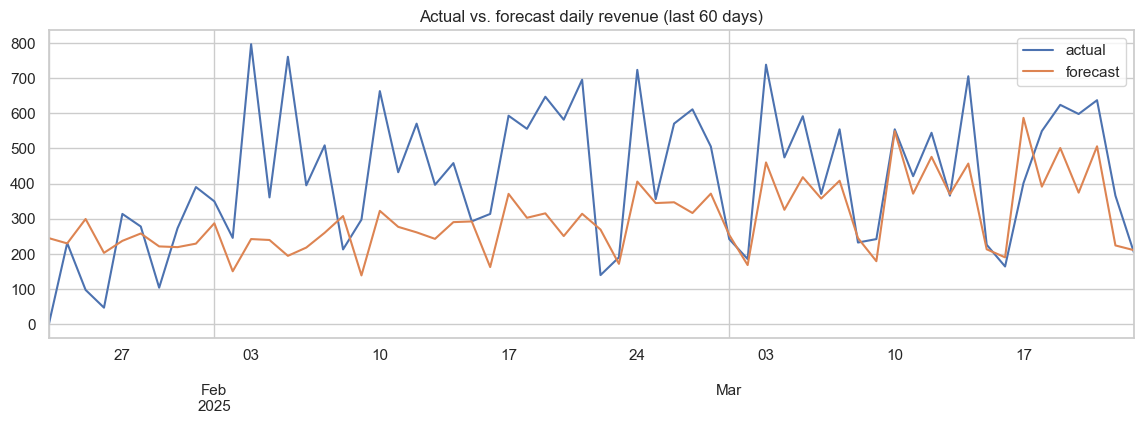

In [31]:
# Build a daily series including zero-sale days
series = daily.copy()

# Predict each day with the mean of the same weekday over the previous 8 weeks
preds = pd.Series(index=series.index, dtype=float)
for d in series.index[56:]:
    same_weekday = [series.get(d - pd.Timedelta(weeks=k)) for k in range(1, 9)]
    preds[d] = np.nanmean(same_weekday)

eval_df = pd.DataFrame({"actual": series, "forecast": preds}).dropna()

# Compare against a naive "average of everything" baseline
mae_model = (eval_df["actual"] - eval_df["forecast"]).abs().mean()
mae_mean  = (eval_df["actual"] - series.mean()).abs().mean()
print(f"MAE, weekday-average forecast: {mae_model:.1f}")
print(f"MAE, overall-average baseline: {mae_mean:.1f}")

eval_df.tail(60).plot(figsize=(14, 4), title="Actual vs. forecast daily revenue (last 60 days)")
plt.show()

The weekday forecast does **not** beat a flat average (the errors are essentially the same), which shows how noisy daily sales are and how little weekly pattern there is to exploit. Proper forecasting would need more history (at least two full years to learn seasonality) and external drivers such as weather, holidays and promotions.

## 7. Key Takeaways

1. **Scale:** about 3,636 transactions and roughly 115,400 in revenue over 381 selling days (about 303 per day, about 32 per transaction).
2. **Products:** Latte (24% of revenue) and Americano with Milk (22%) lead. Espresso contributes only about 2%.
3. **Seasonality:** October and February are the strongest months, January the weakest. March 2025 is a partial month.
4. **Timing:** weekdays earn significantly more than weekends (Sunday is the quietest), though differences between individual weekdays are not significant. The busiest hour is 10:00.
5. **Preferences shift through the day:** Cortado and Americano with Milk skew morning, while milk-based and chocolate drinks skew evening.
6. **Payment:** about 98% of transactions are by card.
7. **Prices changed during the year:** prices dipped in summer 2024 and rose in autumn, so revenue trends mix volume and price effects.
8. **Customers:** about 59% of card IDs appear only once, but the 41% who return account for about 78% of card sales, and the top 10% of customers generate about half of card revenue.

### Limitations and next steps
- The currency and the reason for price changes are not in the data.
- Cash customers cannot be tracked, and some card IDs may be shared.
- Less than 13 months of data is not enough to separate seasonality from growth.
- A simple weekday-average forecast did not beat a flat average, so forecasting needs more data.
- Next steps: price elasticity analysis, customer segmentation (RFM), basket analysis (drinks bought together by the same card on the same day) and a proper time-series forecast.